In [1]:
import pandas as pd
import numpy as np
import rasterio

In [2]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [3]:
data = pd.read_csv("/content/drive/MyDrive/collab/f2/soil_climat_fire_grid_Elev_merged.csv")

In [4]:
raster = rasterio.open("/content/drive/MyDrive/big_data_project/Data/Land_Cover/landcover_portugal_300m.tif")

In [6]:
data.columns

Index(['latitude', 'longitude', 'landcover', 'SMU_ID', 'HWSD2_SMU_ID',
       'COARSE', 'SAND', 'SILT', 'CLAY', 'TEXTURE_USDA', 'TEXTURE_SOTER',
       'BULK', 'ORG_CARBON', 'PH_WATER', 'CN_RATIO', 'CEC_SOIL', 'CEC_CLAY',
       'CEC_EFF', 'BSAT', 'ALUM_SAT', 'ESP', 'TCARBON_EQ', 'GYPSUM',
       'ELEC_COND', 'in_fire', 'prec_automne', 'prec_ete', 'prec_hiver',
       'prec_printemps', 'tmax_automne', 'tmax_ete', 'tmax_hiver',
       'tmax_printemps', 'tmin_automne', 'tmin_ete', 'tmin_hiver',
       'tmin_printemps', 'Elevation'],
      dtype='object')

In [16]:
cord = ["latitude", "longitude"]
soil = ['HWSD2_SMU_ID','SMU_ID',
       'COARSE', 'SAND', 'SILT', 'CLAY', 'TEXTURE_USDA',
       'BULK', 'ORG_CARBON', 'PH_WATER', 'CN_RATIO', 'CEC_SOIL', 'CEC_CLAY',
       'CEC_EFF', 'BSAT', 'ALUM_SAT', 'ESP', 'TCARBON_EQ', 'GYPSUM',
       'ELEC_COND']
soil_non_numeric = ["TEXTURE_USDA"]

fire = ["in_fire"]

elev = ["Elevation"]

climat = ['prec_hiver', 'prec_printemps', 'prec_ete',
       'prec_automne', 'tmin_hiver', 'tmin_printemps', 'tmin_ete',
       'tmin_automne', 'tmax_hiver', 'tmax_printemps', 'tmax_ete',
       'tmax_automne'] 

land = ["landcover"]

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import skew


cmap_dict = {
    
    'COARSE': 'Greys', 
    'SAND': 'YlOrRd', 
    'SILT': 'YlGn', 
    'CLAY': 'YlOrBr', 
    'BULK': 'Purples', 
    'ORG_CARBON': 'Greens', 
    'PH_WATER': 'RdYlGn', 
    'CN_RATIO': 'YlGnBu', 
    'CEC_SOIL': 'GnBu', 
    'CEC_CLAY': 'GnBu',
    'CEC_EFF': 'GnBu', 
    'BSAT': 'PuBu', 
    'ALUM_SAT': 'Reds', 
    'ESP': 'Oranges', 
    'TCARBON_EQ': 'Greens', 
    'GYPSUM': 'Purples',
    'ELEC_COND': 'YlGnBu',
    
   
    'prec_hiver': 'Blues', 'prec_printemps': 'Blues', 'prec_ete': 'Blues', 'prec_automne': 'Blues',
    'tmin_hiver': 'coolwarm', 'tmin_printemps': 'coolwarm', 'tmin_ete': 'coolwarm', 'tmin_automne': 'coolwarm',
    'tmax_hiver': 'YlOrRd', 'tmax_printemps': 'YlOrRd', 'tmax_ete': 'YlOrRd', 'tmax_automne': 'YlOrRd',

    'Elevation': 'terrain',
    'in_fire': 'Reds',
    'landcover': 'tab20'
}

def analyze_and_plot_portugal(prop, df_source, bins=30):
    # 1. Vérification des données
    if prop not in df_source.columns:
        return None
    
    vals = df_source[prop].dropna()
    if vals.empty:
        print(f"Données vides pour {prop}")
        return None

    # 2. Préparation de la figure
    fig = plt.figure(figsize=(16, 10))
    gs = fig.add_gridspec(2, 2, width_ratios=[1.2, 1], height_ratios=[1, 1])
    
    # --- A. LA CARTE (Utilisation de latitude/longitude du CSV) ---
    ax_map = fig.add_subplot(gs[:, 0])
    
    # On récupère la couleur dans le dict, ou viridis par défaut
    # Logique simplifiée : si le nom contient la clé du dict
    current_cmap = 'viridis'
    for key in cmap_dict:
        if key in prop:
            current_cmap = cmap_dict[key]
            break

    sc = ax_map.scatter(df_source['longitude'], df_source['latitude'], 
                        c=df_source[prop], cmap=current_cmap, s=1, alpha=0.8)
    
    ax_map.set_title(f"Répartition Spatiale : {prop}", fontsize=15, fontweight='bold')
    ax_map.set_aspect('equal')
    plt.colorbar(sc, ax=ax_map, orientation='horizontal', fraction=0.04, pad=0.07)
    
    # --- B. HISTOGRAMME ---
    ax_hist = fig.add_subplot(gs[0, 1])
    if prop == 'landcover' or prop == 'in_fire':
        sns.countplot(x=df_source[prop], ax=ax_hist, palette='viridis')
    else:
        sns.histplot(vals, bins=bins, kde=True, color="teal", ax=ax_hist)
    ax_hist.set_title(f"Distribution / Fréquence")

    # --- C. BOXPLOT ---
    ax_box = fig.add_subplot(gs[1, 1])
    sns.boxplot(x=vals, color="coral", ax=ax_box)
    ax_box.set_title(f"Statistiques descriptives (Quartiles)")

    plt.suptitle(f"Analyse Variable : {prop}", fontsize=20, y=0.98)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

    return {"mean": vals.mean(), "std": vals.std()}


groups = [soil[2:], climat, elev, land, fire] 


# Soil

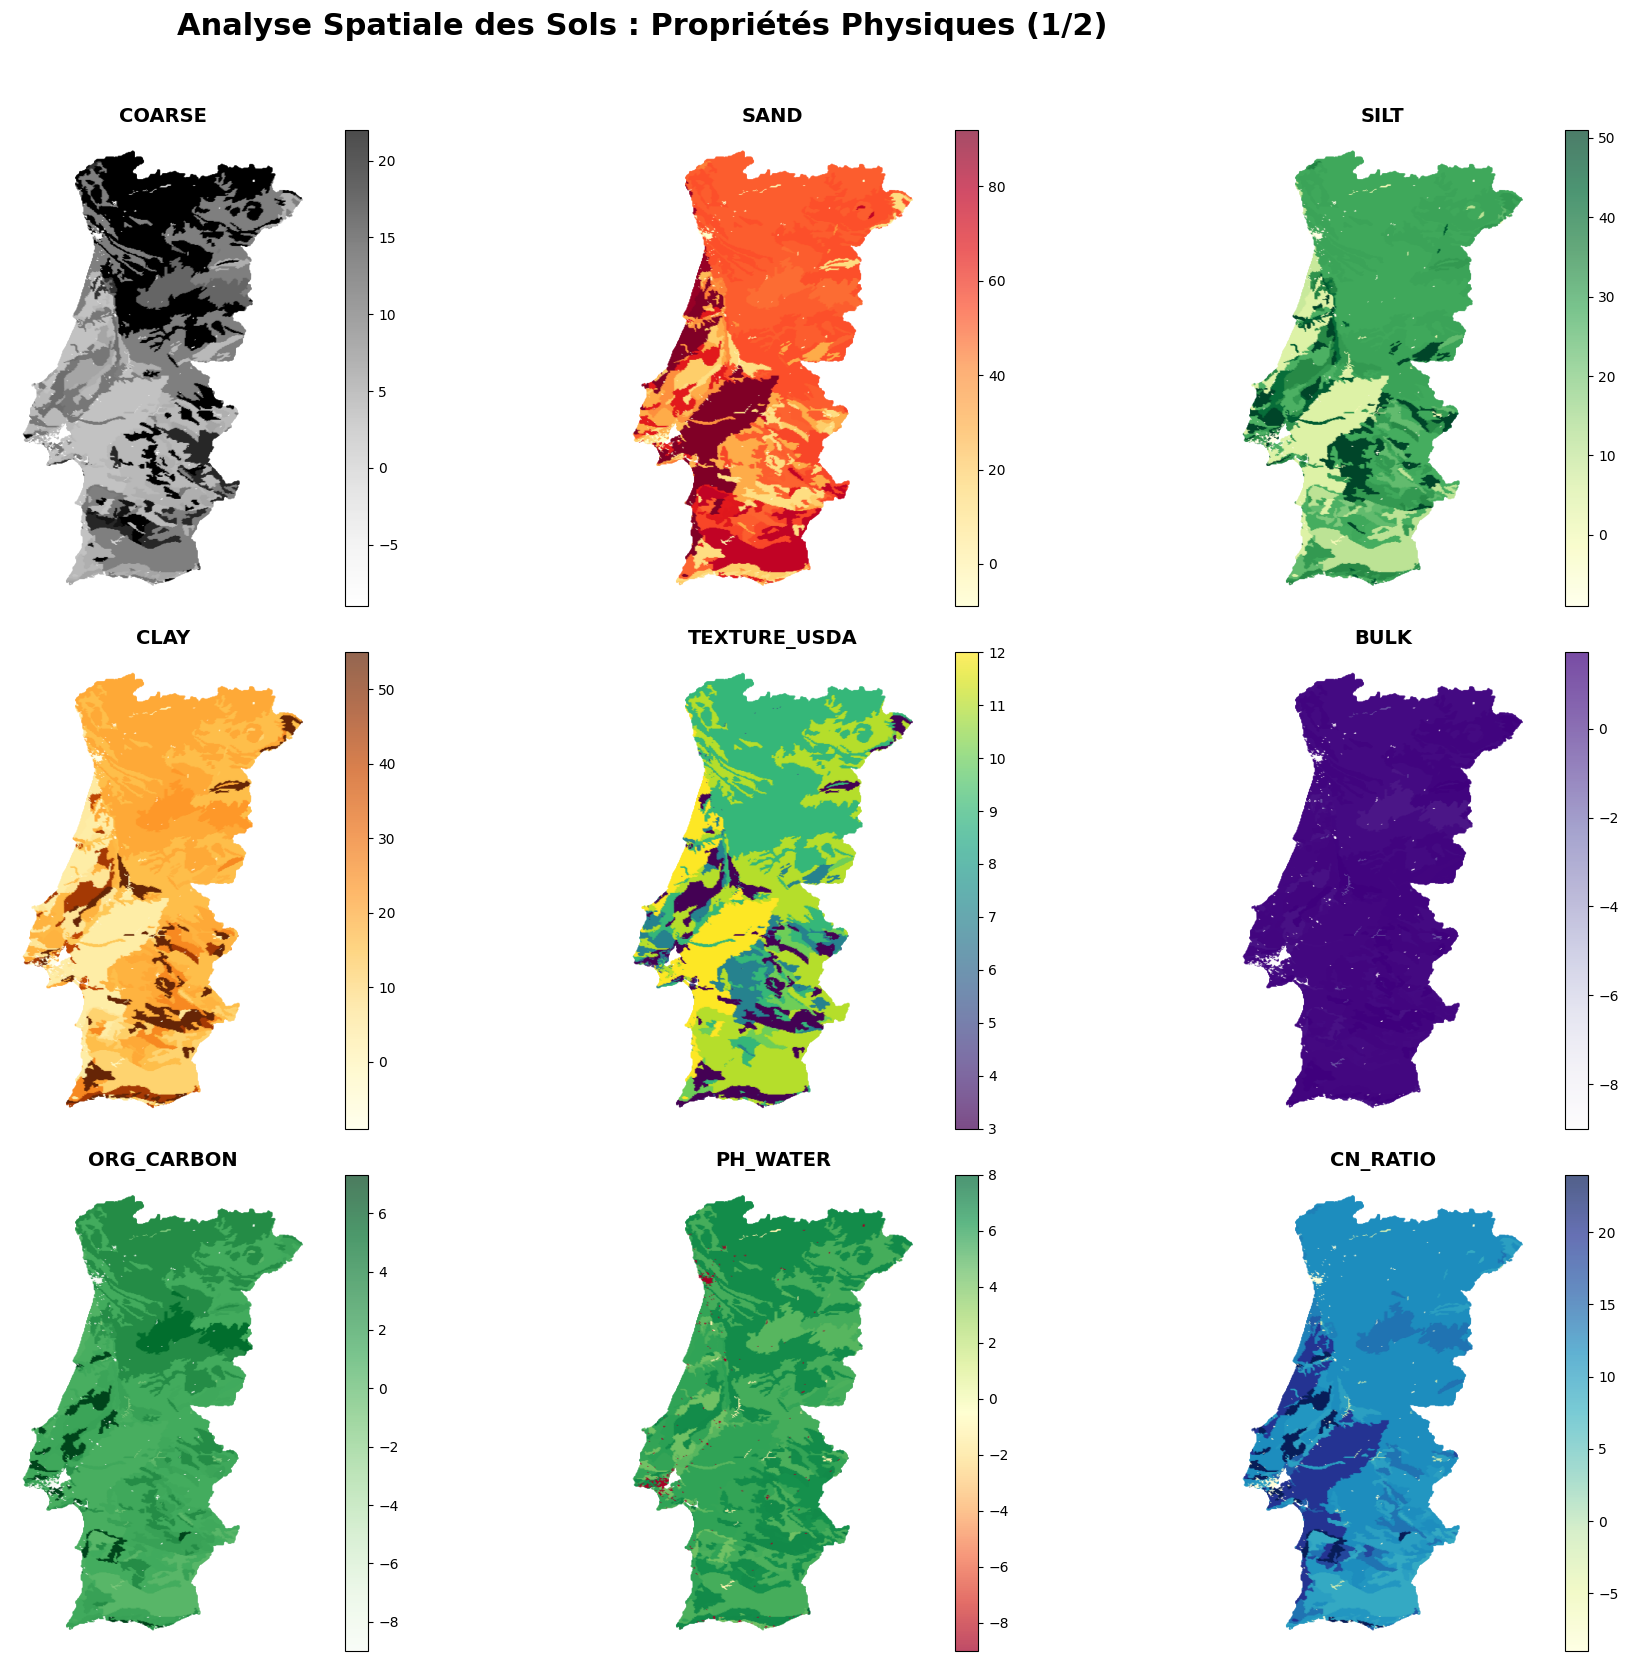

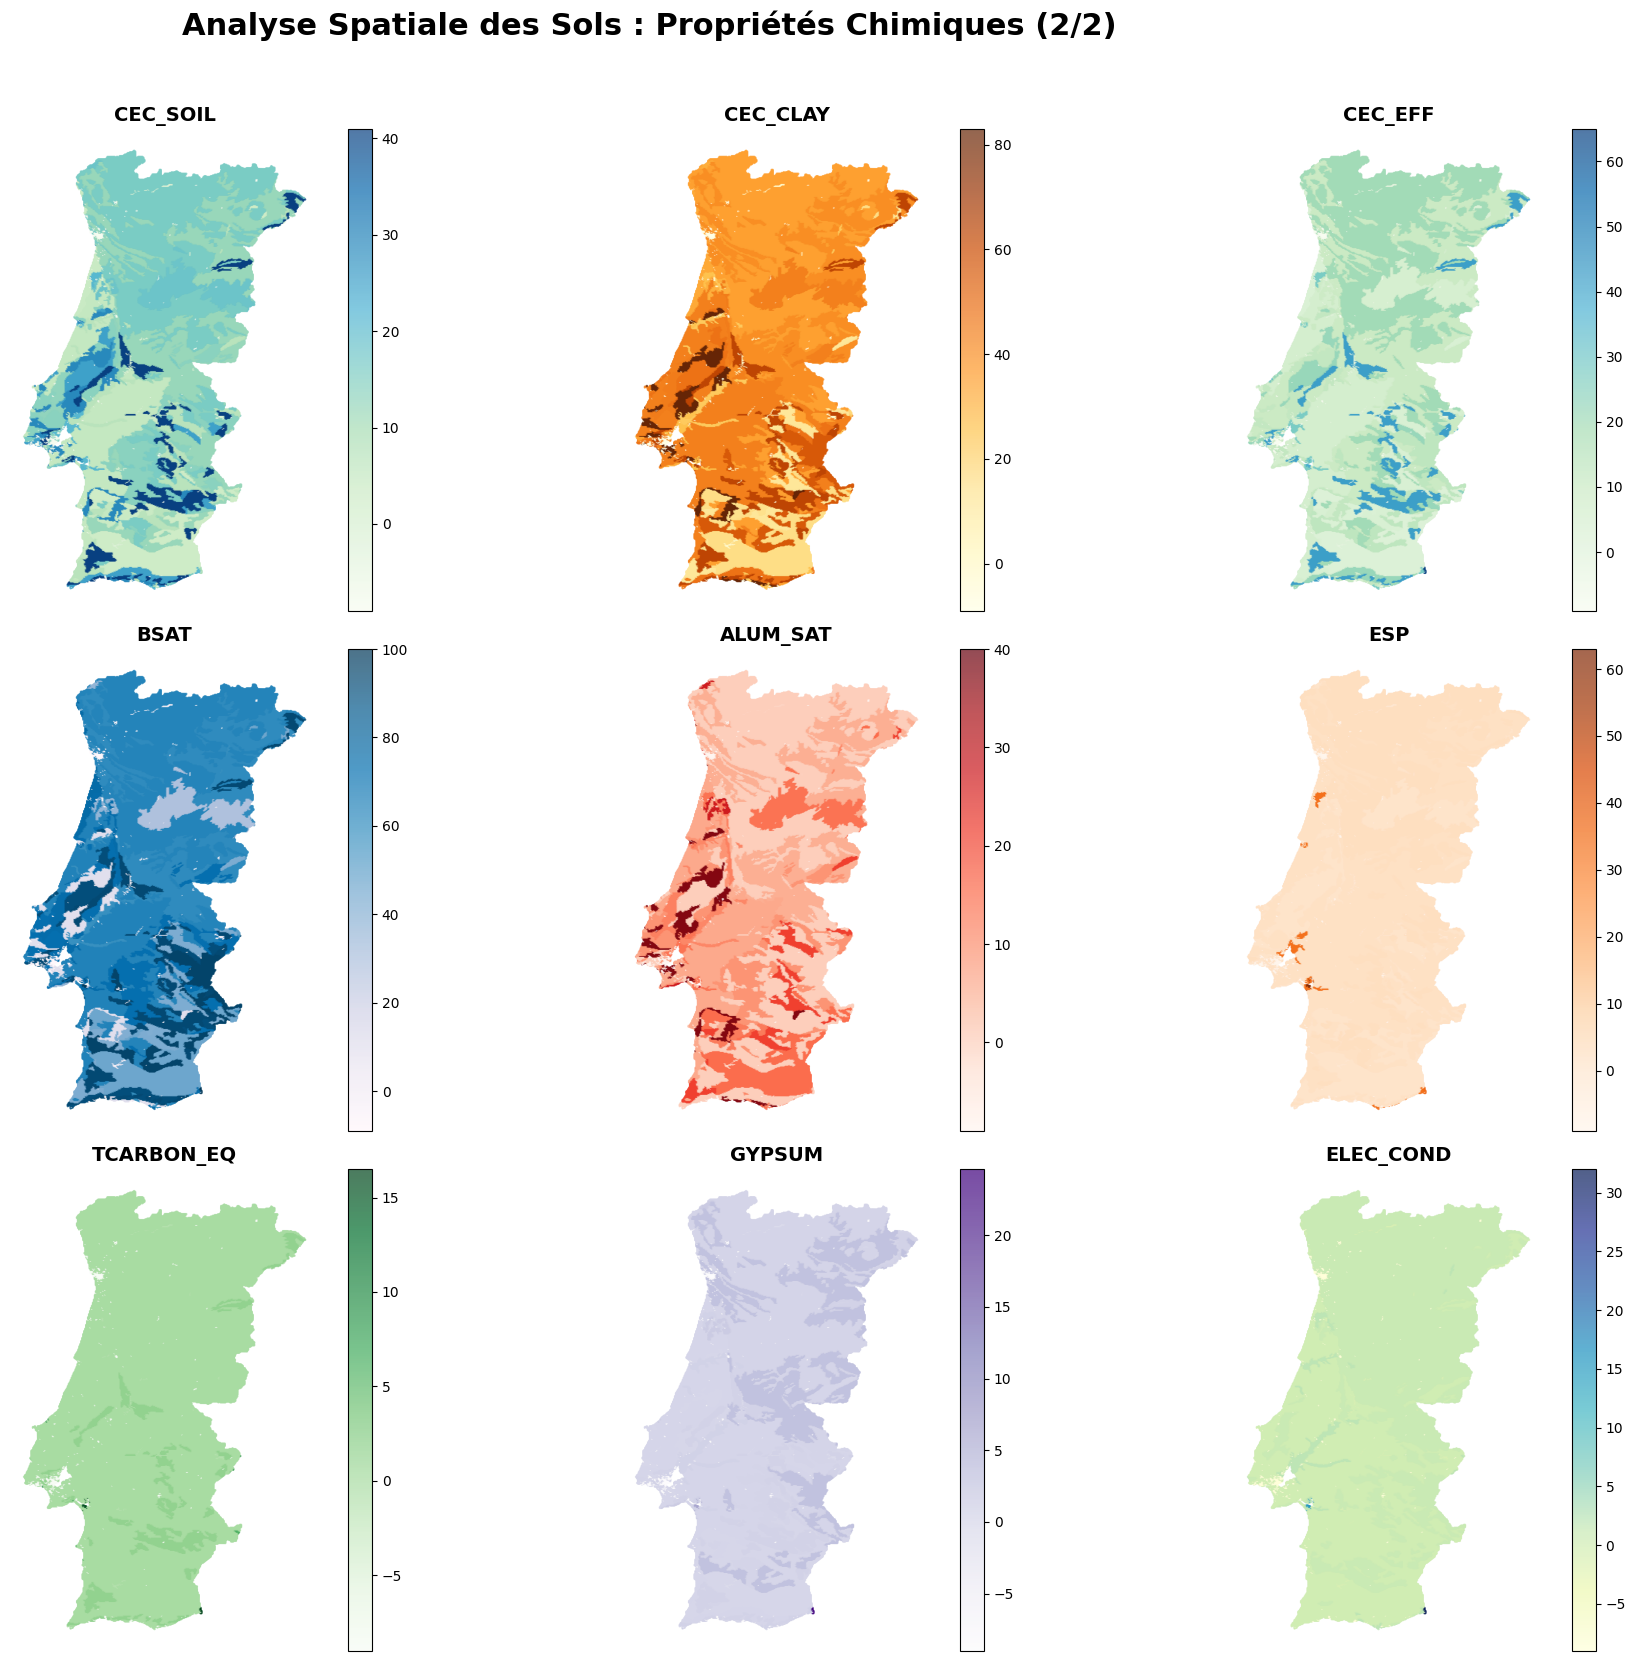

In [ ]:
import math

def plot_grid_soil(variables, df_source, title_suffix="Partie 1"):
  
    vars_to_plot = variables[:9]
    num_vars = len(vars_to_plot)
  
    fig, axes = plt.subplots(3, 3, figsize=(20, 18))
    axes = axes.flatten() 

    for i, prop in enumerate(vars_to_plot):
        ax = axes[i]
        
        # 1. Nettoyage des données
        df_clean = df_source[['longitude', 'latitude', prop]].dropna()
        
        if df_clean.empty:
            ax.set_title(f"{prop} (Pas de données)")
            ax.axis('off')
            continue

  
        current_cmap = 'viridis'
        for key in cmap_dict:
            if key in prop:
                current_cmap = cmap_dict[key]
                break
        
        
        sc = ax.scatter(df_clean['longitude'], df_clean['latitude'], 
                        c=df_clean[prop], cmap=current_cmap, s=0.5, alpha=0.7)
        
        # 4. Esthétique de la carte
        ax.set_title(f"{prop}", fontsize=14, fontweight='bold')
        ax.set_aspect('equal')
        ax.axis('off')
        
        plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)

    for j in range(i + 1, 9):
        axes[j].axis('off')

    plt.suptitle(f"Analyse Spatiale des Sols : {title_suffix}", fontsize=22, y=0.95, fontweight='black')
    plt.tight_layout(rect=[0, 0.03, 1, 0.93])
    plt.show()




soil_numeric = [v for v in soil if v not in ['latitude', 'longitude', 'HWSD2_SMU_ID', 'SMU_ID']]


plot_grid_soil(soil_numeric[:9], data, title_suffix="Propriétés Physiques (1/2)")


plot_grid_soil(soil_numeric[9:18], data, title_suffix="Propriétés Chimiques (2/2)")

# Climat

📊 Génération du rapport pour prec_hiver...


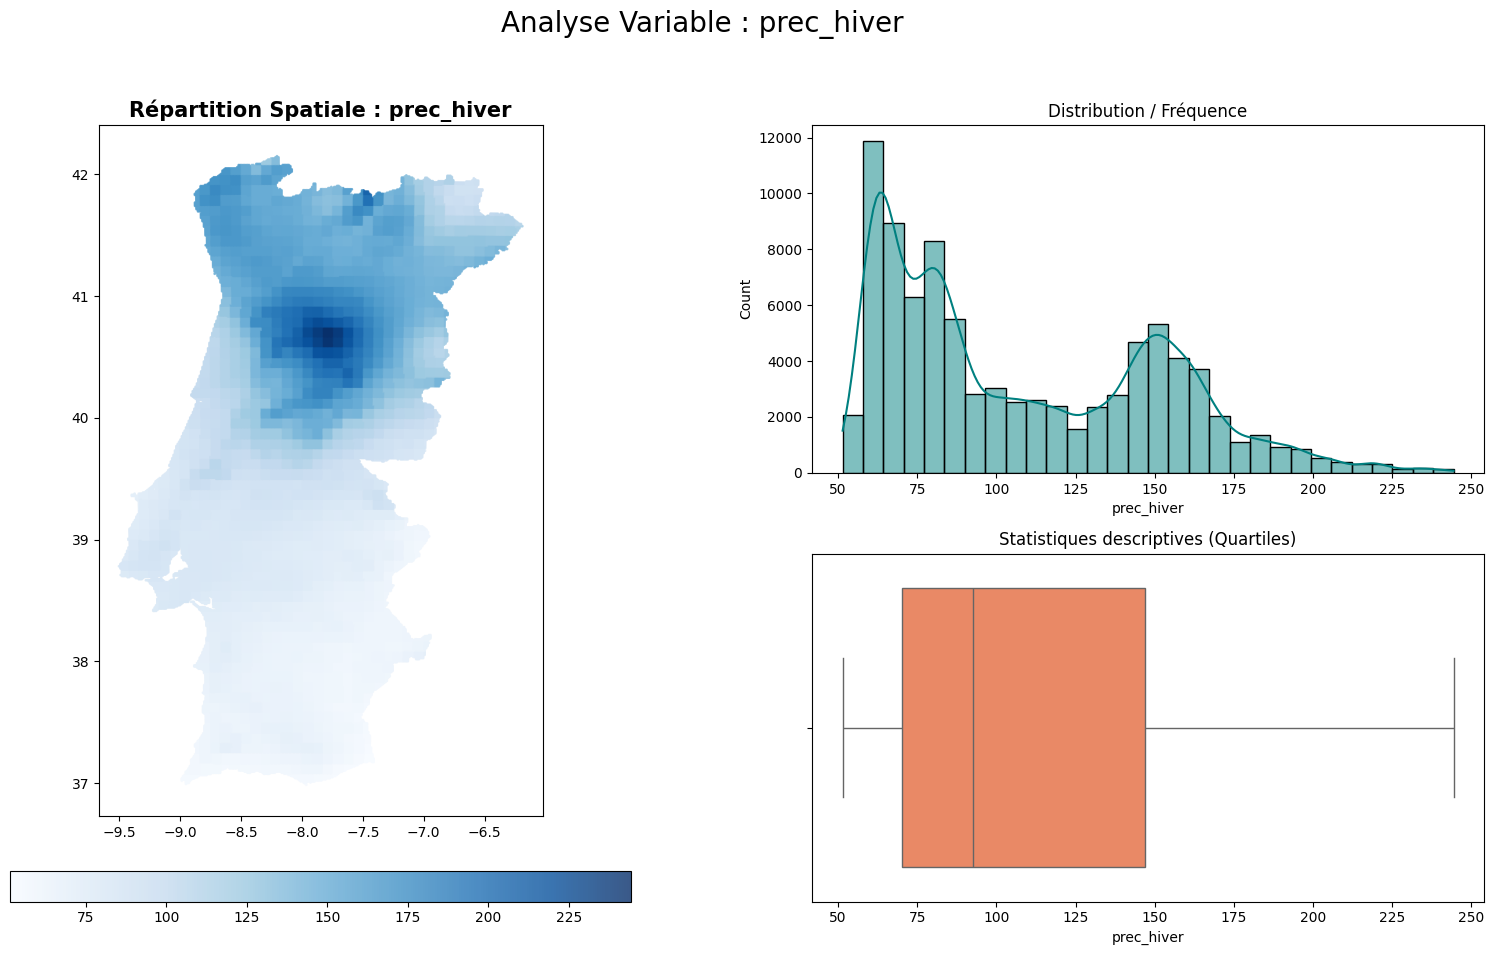

📊 Génération du rapport pour prec_printemps...


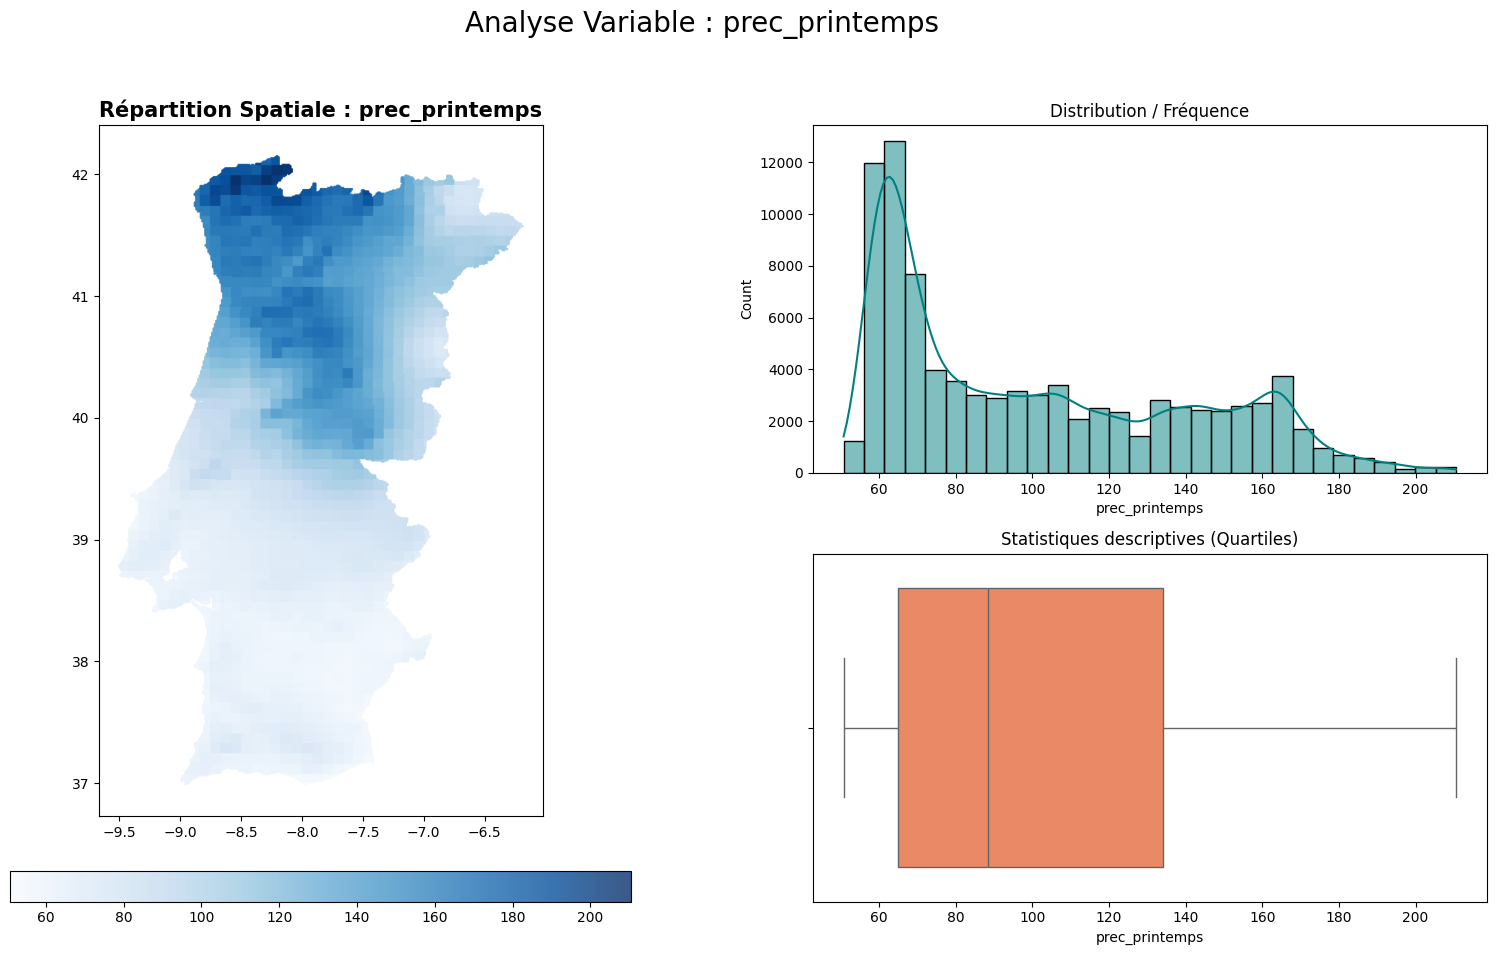

📊 Génération du rapport pour prec_ete...


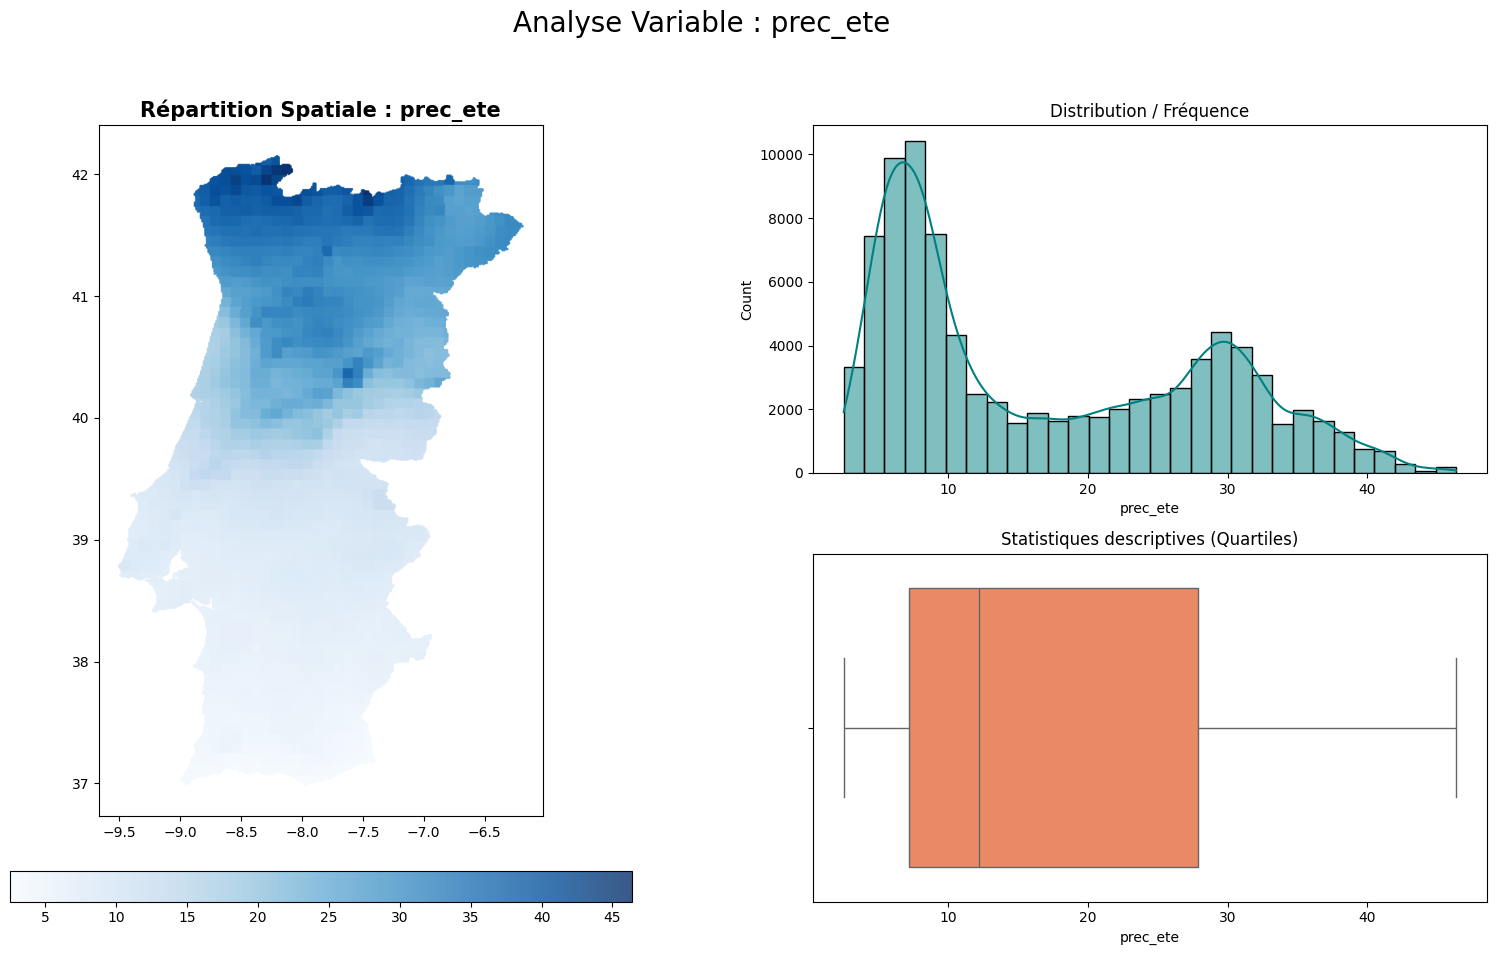

📊 Génération du rapport pour prec_automne...


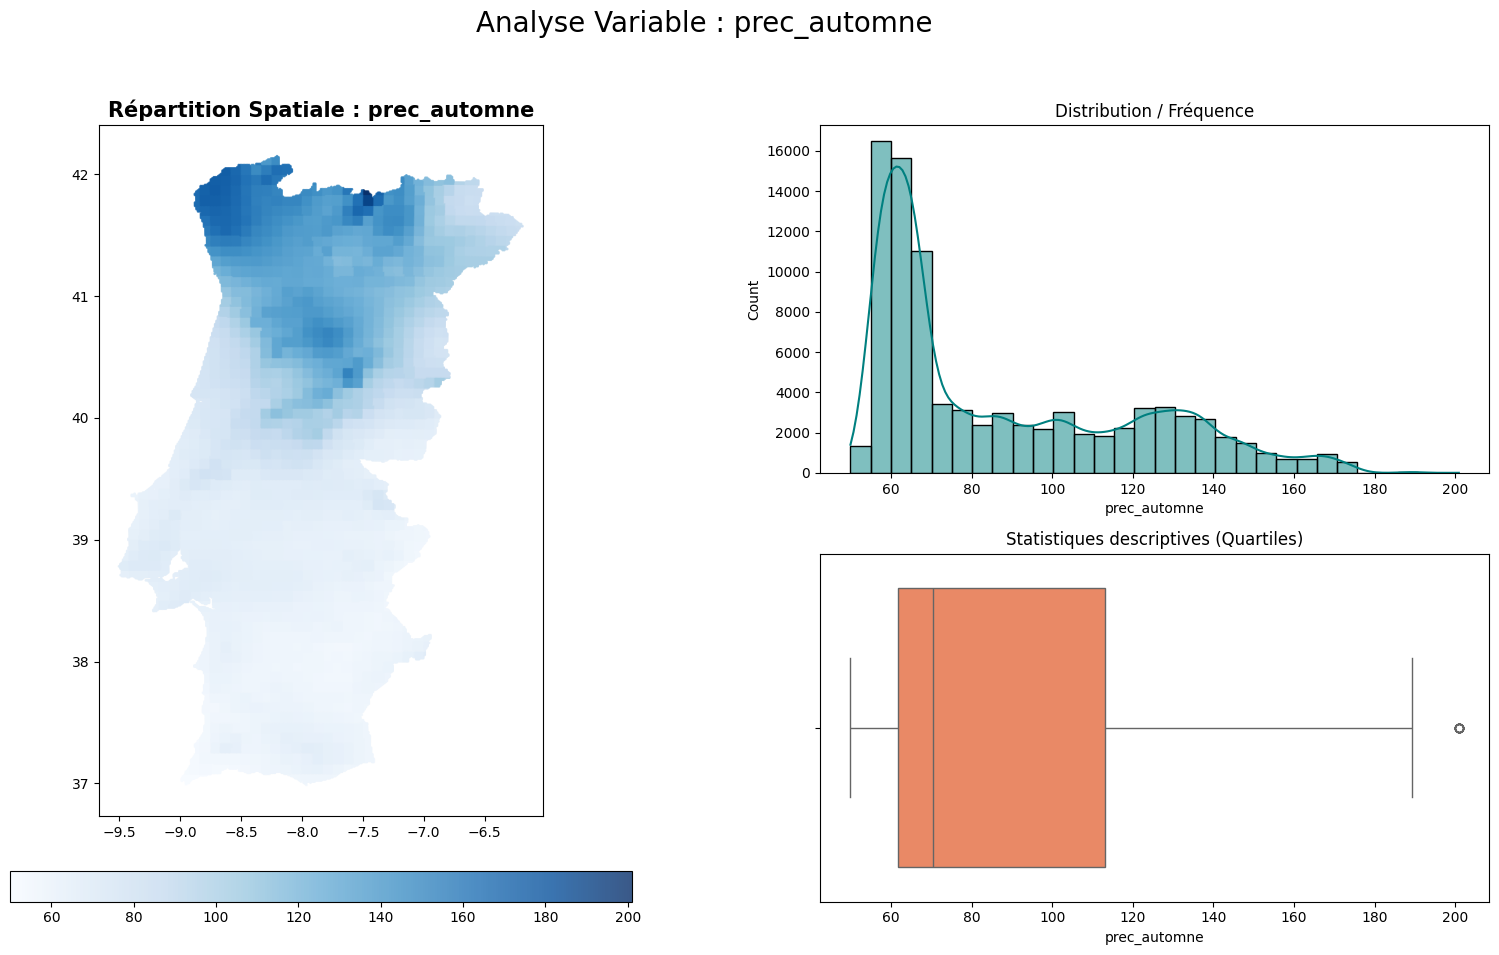

📊 Génération du rapport pour tmin_hiver...


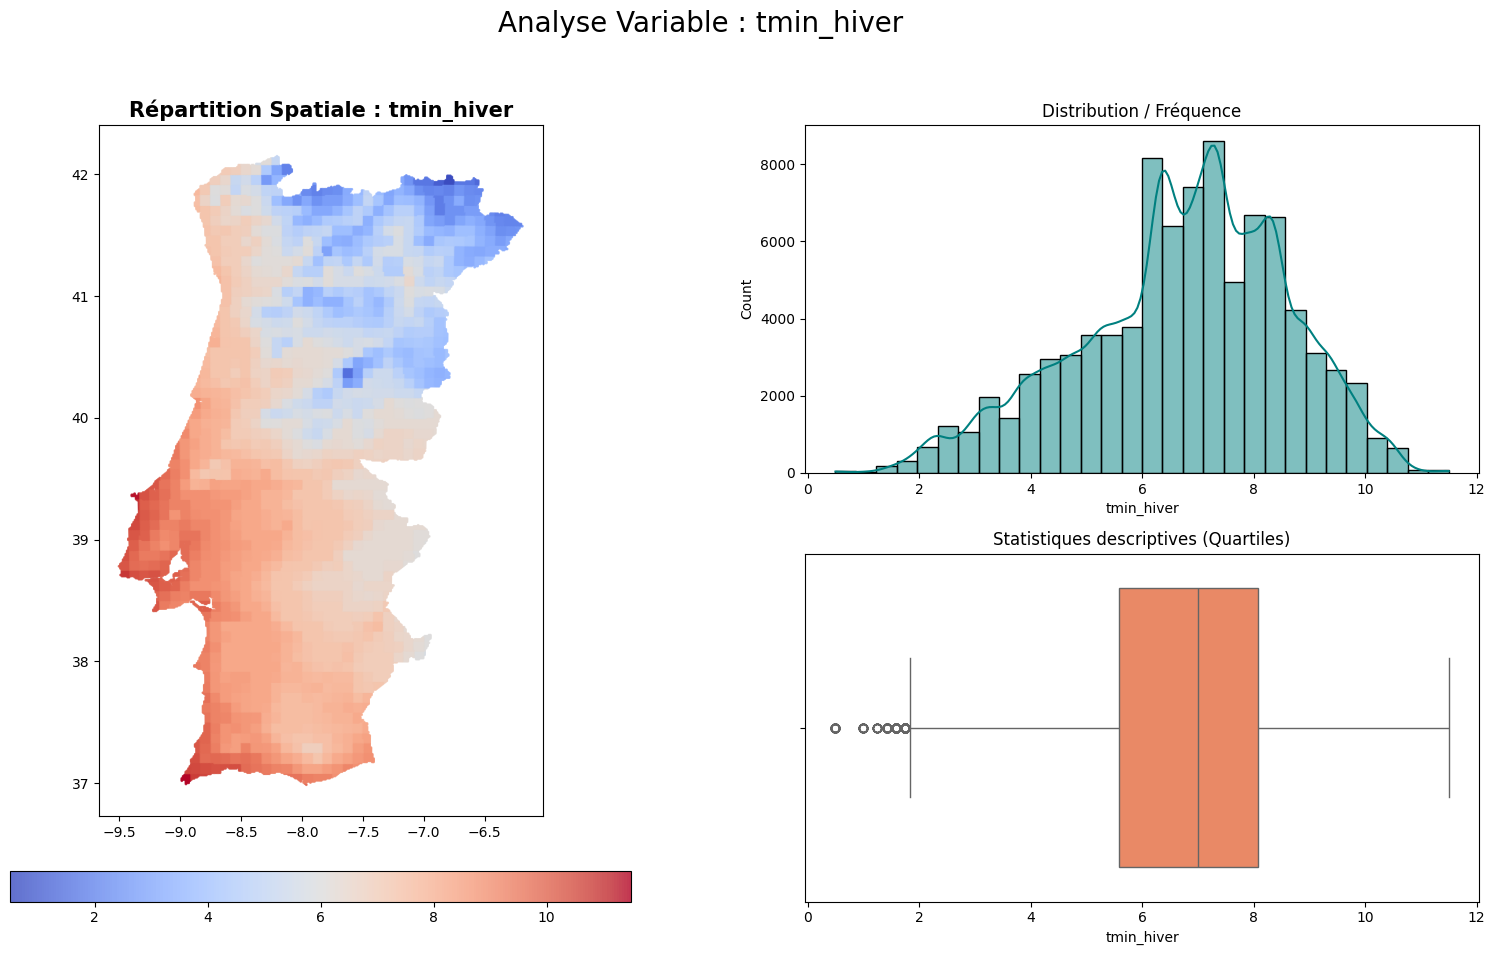

📊 Génération du rapport pour tmin_printemps...


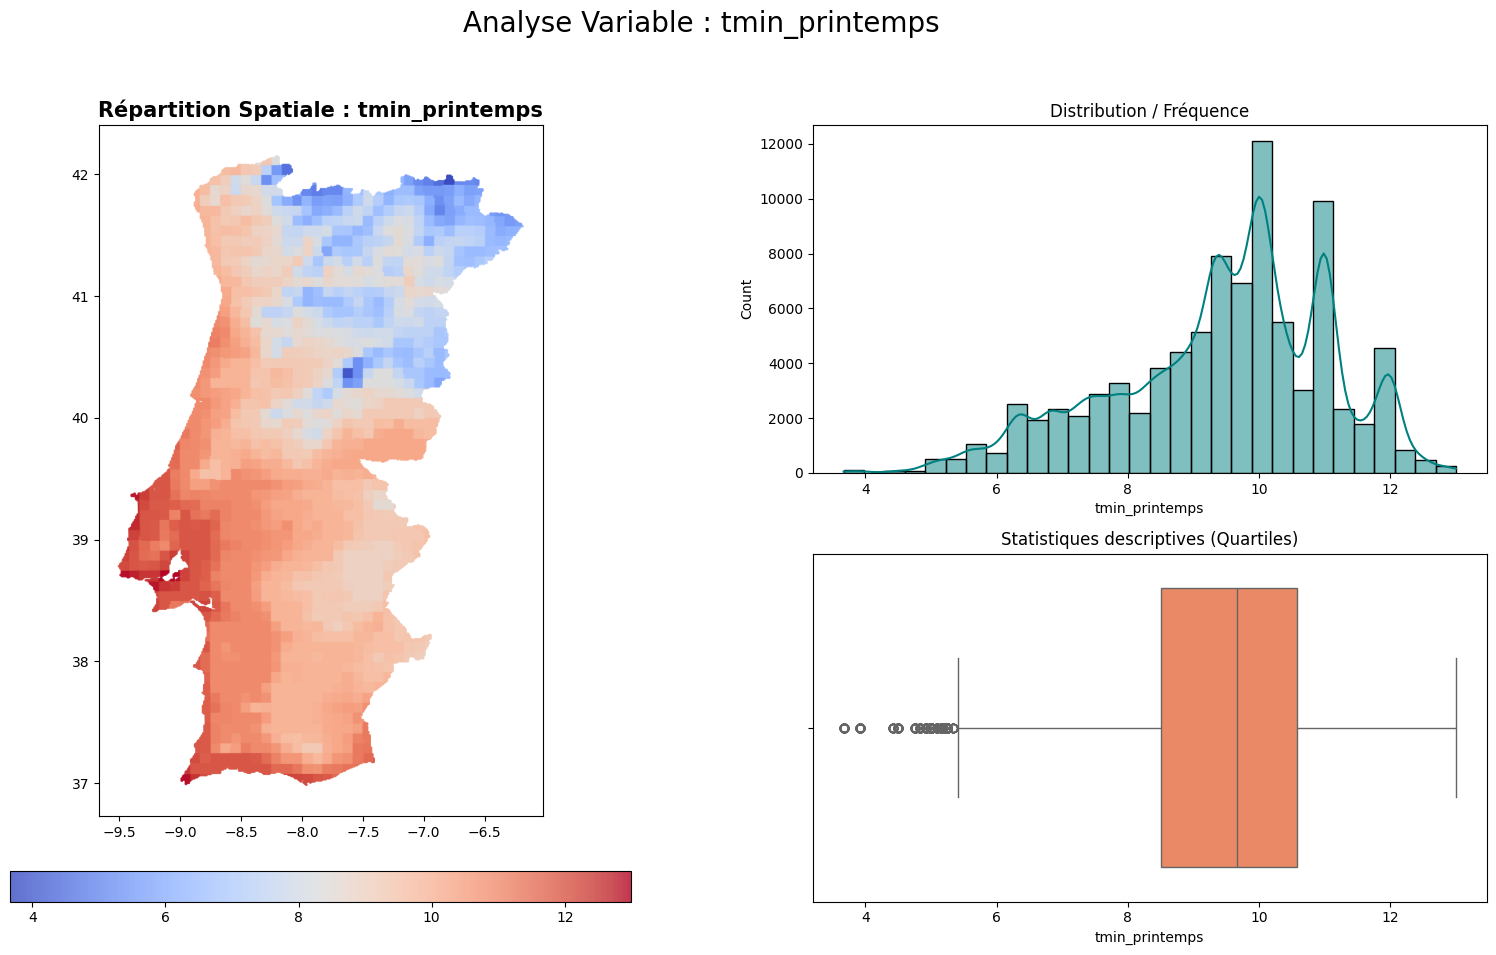

📊 Génération du rapport pour tmin_ete...


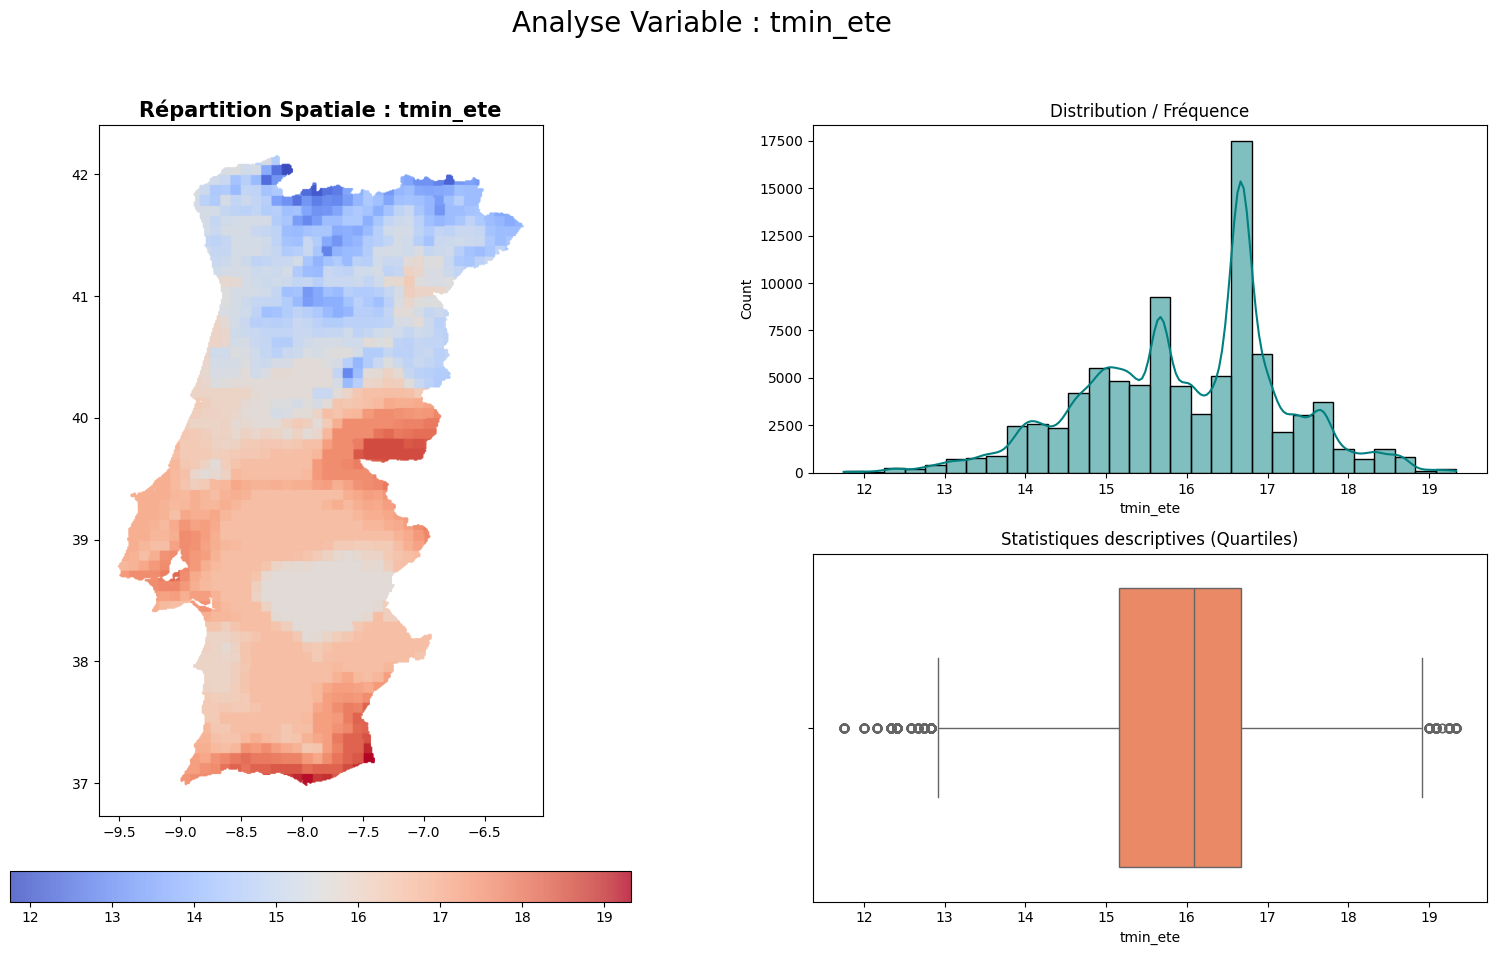

📊 Génération du rapport pour tmin_automne...


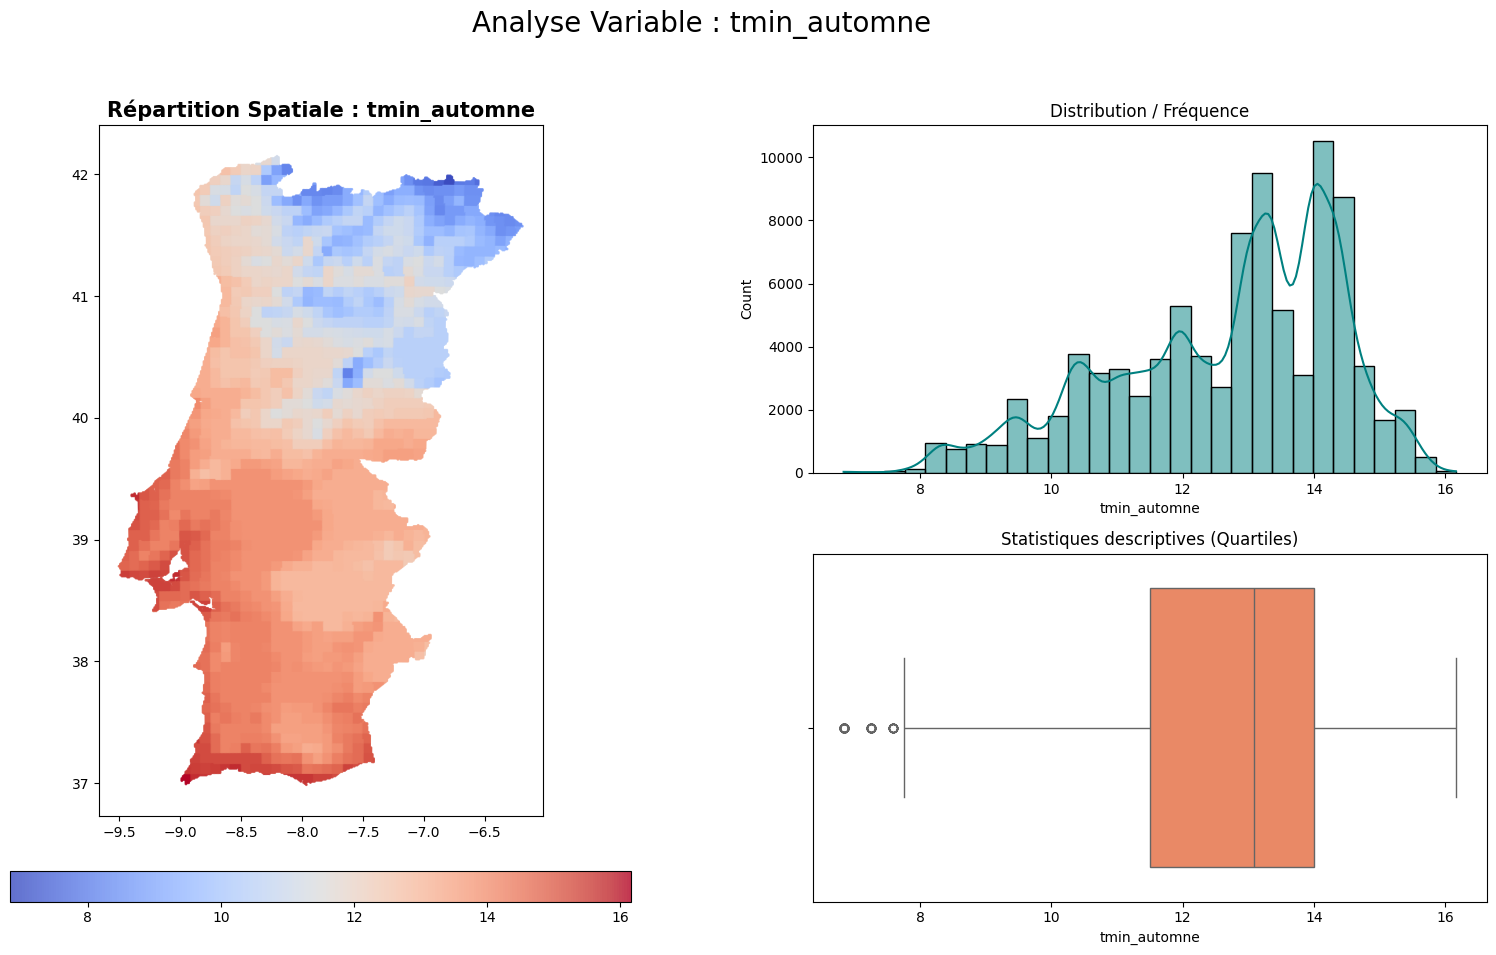

📊 Génération du rapport pour tmax_hiver...


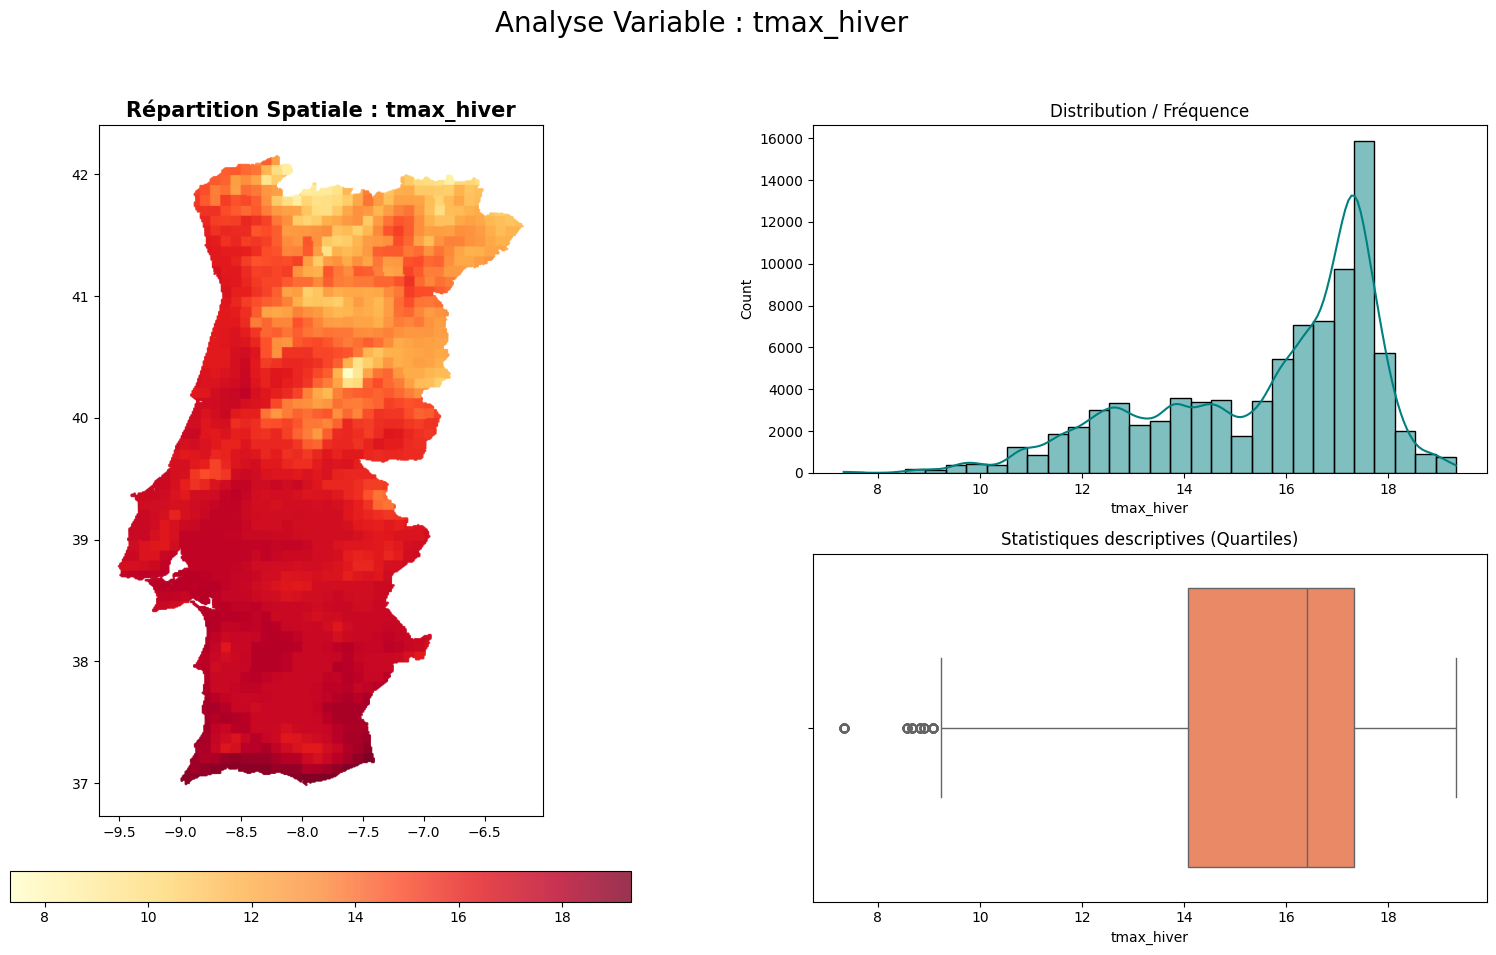

📊 Génération du rapport pour tmax_printemps...


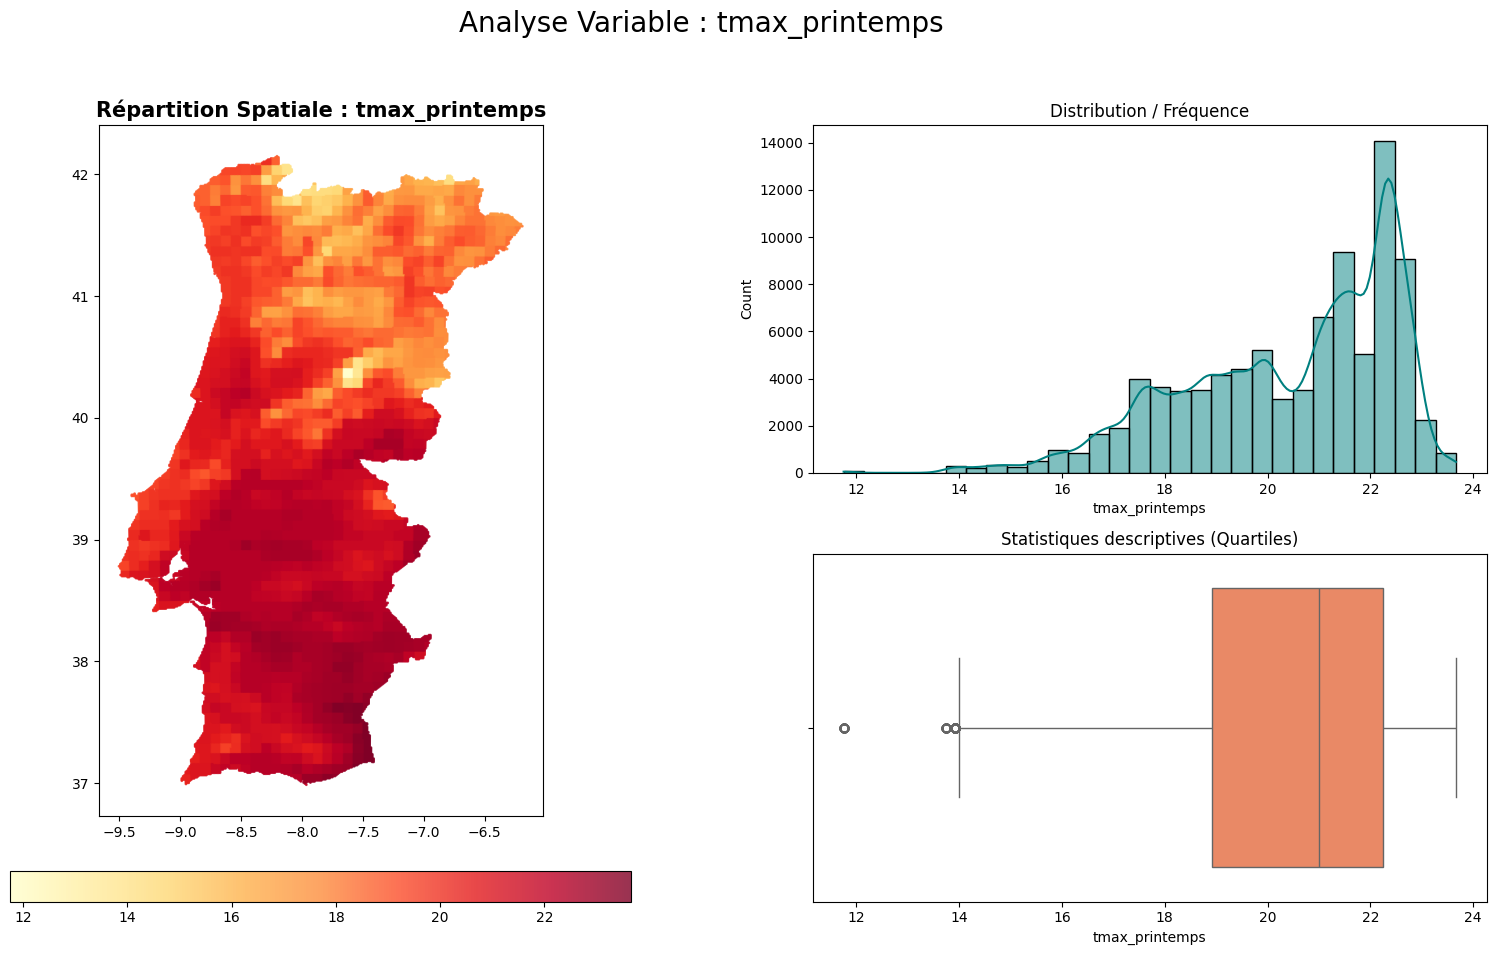

📊 Génération du rapport pour tmax_ete...


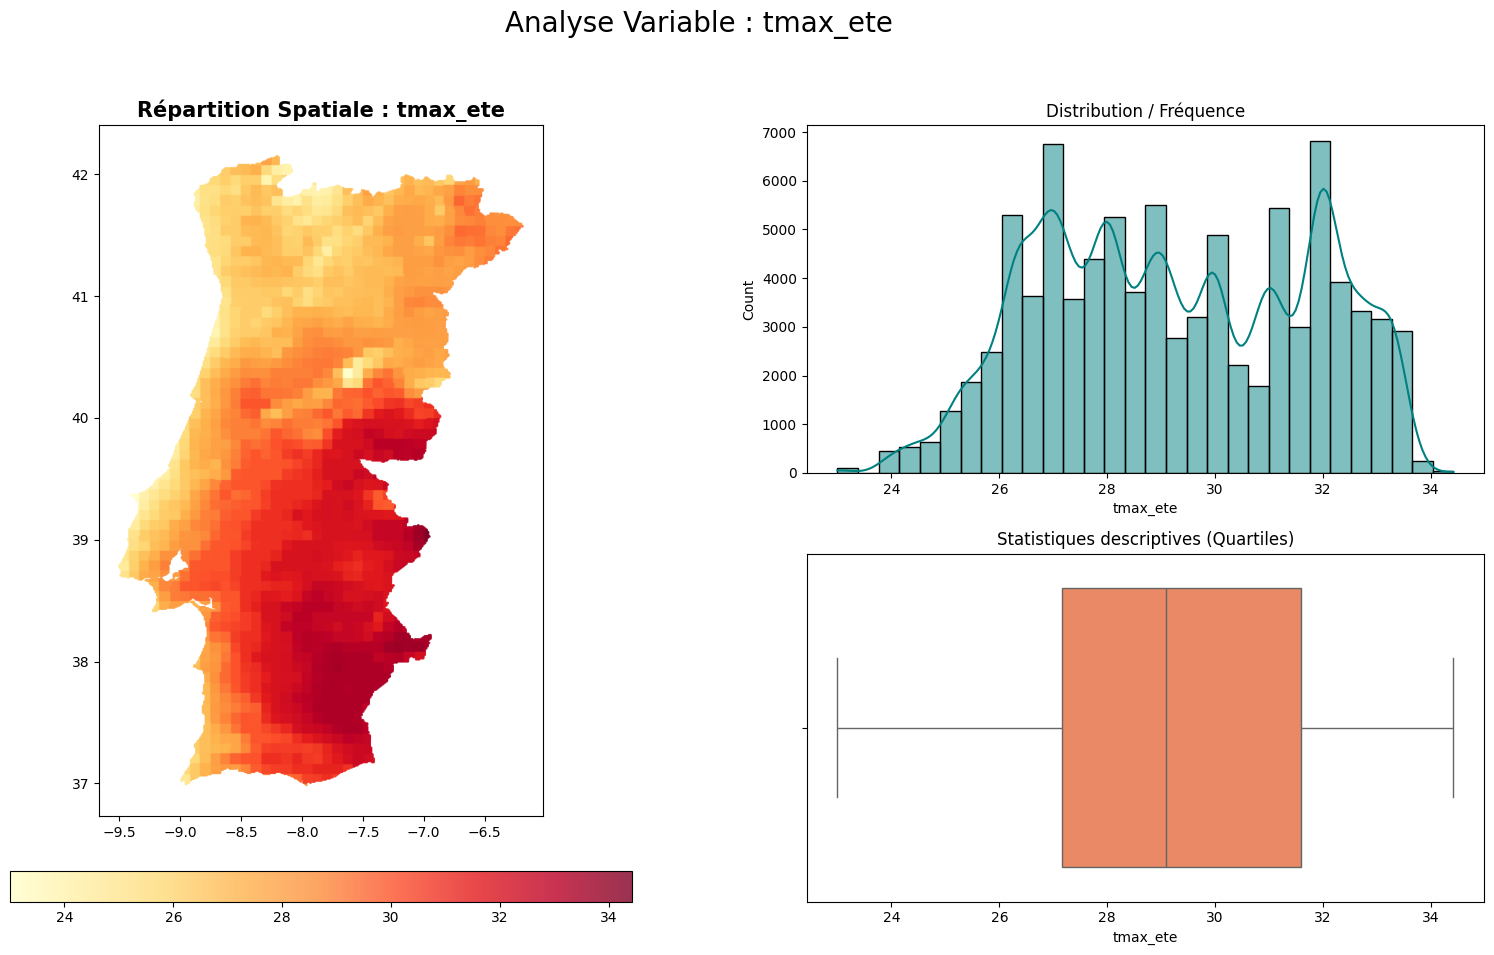

📊 Génération du rapport pour tmax_automne...


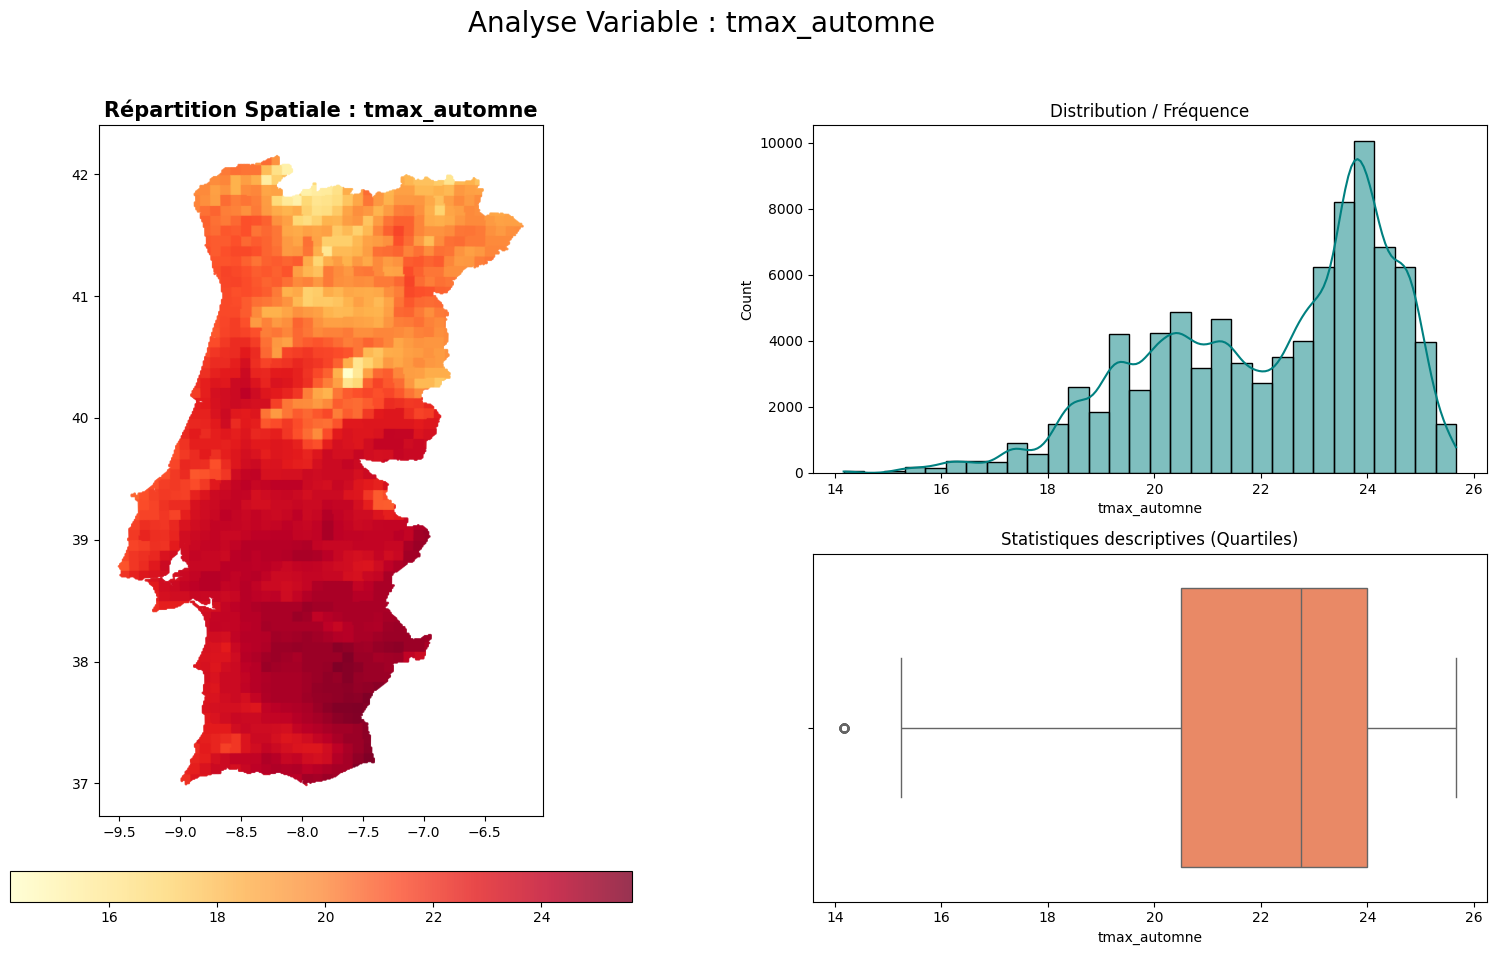

In [22]:
for p in groups[1]:
    if p in data.columns:
        print(f"📊 Génération du rapport pour {p}...")
        analyze_and_plot_portugal(p, data)

# Elevation